In [1]:
# Análisis Exploratorio — Reseñas de Productos

#**Proyecto:** Clasificación de reseñas de productos de 1 a 5 estrellas.

#**Dataset:** SetFit/amazon_reviews_multi_es.

## Objetivos

#1. Examinar la calidad del dataset.
#2. Analizar la distribución de puntuaciones.
#3. Estudiar la longitud de las reseñas.
#4. Identificar las palabras más frecuentes.
#5. Documentar las decisiones de preparación de datos.
#6. Presentar los resultados de los modelos NLP/ML.
import sys
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

DATA_PATH = Path("../data/raw/reviews.csv")

# Permite ejecutar el notebook tanto desde notebooks/ como desde la raíz.
if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/reviews.csv")

df = pd.read_csv(DATA_PATH)

print("Filas:", len(df))
print("Columnas:", df.columns.tolist())
display(df.head())

Filas: 20000
Columnas: ['review_id', 'review_text', 'rating']


,review_id,review_text,rating
0,es_0446108,Pedí la botella por comodidad al salir a pasea...,1
1,es_0328818,"lo compré por ser SONY, pero la calidad de son...",1
2,es_0839092,Decepcionada. El mod venía con claros signos d...,1
3,es_0757233,"Autentica desilusión, no tiene nada que ver co...",1
4,es_0727971,No me hicieron la devolución del producto.,1


In [3]:
print("Valores faltantes:")
display(df.isna().sum().to_frame("faltantes"))

print("Duplicados por texto:")
print(df["review_text"].duplicated().sum())

print("Puntuaciones inválidas:")
print((~df["rating"].isin([1, 2, 3, 4, 5])).sum())

Valores faltantes:


,faltantes
review_id,0
review_text,0
rating,0


Duplicados por texto:
53
Puntuaciones inválidas:
0


,reseñas
rating,
1,4000
2,4000
3,4000
4,4000
5,4000


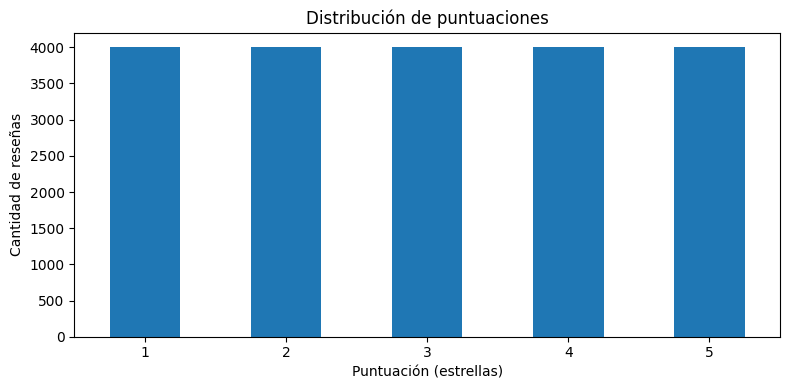

In [4]:
distribution = df["rating"].value_counts().sort_index()

display(distribution.to_frame("reseñas"))

plt.figure(figsize=(8, 4))
distribution.plot(kind="bar")

plt.title("Distribución de puntuaciones")
plt.xlabel("Puntuación (estrellas)")
plt.ylabel("Cantidad de reseñas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

count    20000.000000
mean        27.755050
std         23.676993
min          2.000000
25%         13.000000
50%         22.000000
75%         34.000000
max        458.000000
Name: word_count, dtype: float64

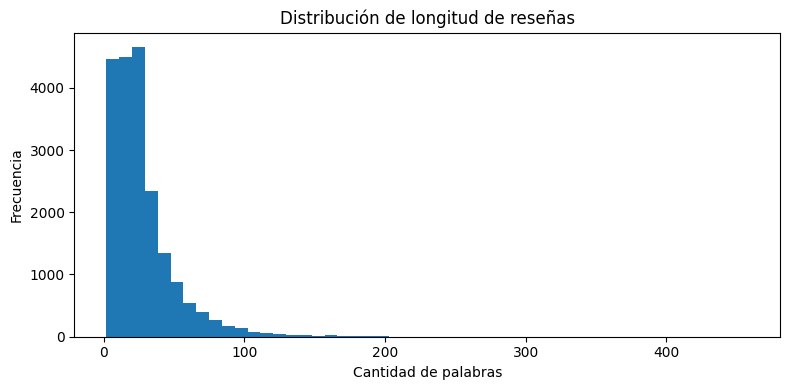

In [5]:
df["word_count"] = df["review_text"].fillna("").str.split().str.len()

display(df["word_count"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["word_count"], bins=50)

plt.title("Distribución de longitud de reseñas")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

,palabra,frecuencia
0,no,15525
1,calidad,3261
2,producto,2447
3,precio,2380
4,sin,1609
5,ni,1177
6,funciona,1089
7,perfecto,916
8,recomiendo,913
9,tiempo,880


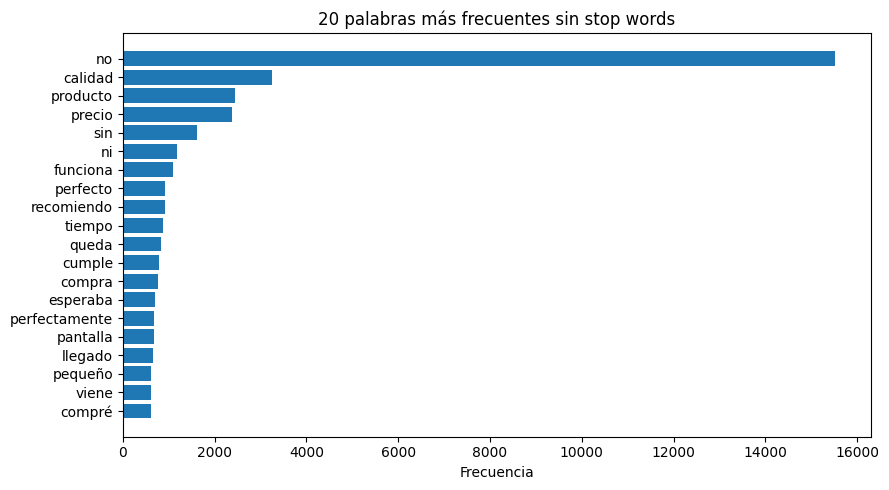

In [6]:
from collections import Counter
from src.nlp.preprocessing import normalize_text, tokenize_text, remove_stopwords

counter = Counter()

for text in df["review_text"].dropna():
    tokens = tokenize_text(normalize_text(text))
    tokens = remove_stopwords(tokens)

    words = [
        token for token in tokens
        if token.isalpha() and len(token) > 1
    ]

    counter.update(words)

top_words = pd.DataFrame(
    counter.most_common(20),
    columns=["palabra", "frecuencia"]
)

display(top_words)

plt.figure(figsize=(9, 5))
plt.barh(top_words["palabra"][::-1], top_words["frecuencia"][::-1])
plt.title("20 palabras más frecuentes sin stop words")
plt.xlabel("Frecuencia")
plt.tight_layout()
plt.show()

In [7]:
metrics_path = Path("models/final/metrics.json")

if not metrics_path.exists():
    metrics_path = Path("../models/final/metrics.json")

with open(metrics_path, encoding="utf-8") as f:
    metrics = json.load(f)

print("Mejores hiperparámetros:")
display(metrics["best_params"])

comparison = pd.DataFrame({
    "Modelo": ["Baseline", "Modelo final"],
    "Accuracy": [
        metrics["baseline"]["accuracy"],
        metrics["final_test"]["accuracy"]
    ],
    "Macro F1": [
        metrics["baseline"]["macro_f1"],
        metrics["final_test"]["macro_f1"]
    ],
    "MAE": [
        metrics["baseline"]["mae"],
        metrics["final_test"]["mae"]
    ]
})

display(comparison)

Mejores hiperparámetros:


{'method': 'stemming', 'ngram_range': [1, 2], 'C': 1.0}

,Modelo,Accuracy,Macro F1,MAE
0,Baseline,0.200552,0.066820,1.995482
1,Modelo final,0.452560,0.448023,0.760040


In [ ]:
## Conclusiones

#- El dataset contiene reseñas en español clasificadas de 1 a 5 estrellas.
#- La muestra utilizada fue seleccionada de manera equilibrada.
#- Se analizaron valores faltantes, duplicados y longitud de textos.
#- La frecuencia de palabras permite identificar vocabulario relevante del dominio.
#- Se compararon configuraciones NLP mediante validación cruzada.
#- El clasificador seleccionado se evaluó sobre un conjunto de prueba independiente.

## Limitaciones

#- Una puntuación de tres estrellas puede representar opiniones ambiguas.
#- Las reseñas de diferentes puntuaciones pueden utilizar vocabulario similar.
#- El dataset equilibrado no necesariamente representa la distribución real de reseñas de una tienda.

SyntaxError: invalid syntax (2829763155.py, line 3)